In [2]:
# Step 1: Environment setup for integrated climate analysis

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# Project directory
PROJECT_DIR = Path(
    r"D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised"
)

# Integrated climate data directory
INTEGRATED_DIR = (
    PROJECT_DIR / "data" / "intermediate" / "integrated_climate"
)

# Spatial data directory
SPATIAL_DIR = PROJECT_DIR / "data" / "spatial"

# Output directory for analysis
RESULTS_DIR = PROJECT_DIR / "results" / "integrated_climate_analysis"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Identify annual integrated datasets
integrated_files = sorted(
    INTEGRATED_DIR.glob("integrated_climate_*.nc")
)

print("Environment setup completed.")
print("Project directory:", PROJECT_DIR)
print("Integrated data directory:", INTEGRATED_DIR)
print("Number of annual files:", len(integrated_files))
print("Analysis output directory:", RESULTS_DIR)

assert len(integrated_files) == 26, "Expected 26 annual NetCDF files."

print("\nFiles identified:")
for file in integrated_files:
    print(file.name)

Environment setup completed.
Project directory: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised
Integrated data directory: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\data\intermediate\integrated_climate
Number of annual files: 26
Analysis output directory: D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\results\integrated_climate_analysis

Files identified:
integrated_climate_2000.nc
integrated_climate_2001.nc
integrated_climate_2002.nc
integrated_climate_2003.nc
integrated_climate_2004.nc
integrated_climate_2005.nc
integrated_climate_2006.nc
integrated_climate_2007.nc
integrated_climate_2008.nc
integrated_climate_2009.nc
integrated_climate_2010.nc
integrated_climate_2011.nc
integrated_climate_2012.nc
integrated_climate_2013.nc
integrated_climate_2014.nc
integrated_climate_2015.nc
in

In [3]:
# Step 2: Load and combine all annual integrated datasets

annual_datasets = [
    xr.open_dataset(file)
    for file in integrated_files
]

climate_ds = xr.concat(
    annual_datasets,
    dim="time"
).sortby("time")

# Basic dataset information
print("Full-period dataset loaded.")
print("-" * 50)

print("Time steps:", climate_ds.sizes["time"])
print("Spatial nodes:", climate_ds.sizes["node"])
print("Variables:", list(climate_ds.data_vars))

print("Start date:", pd.Timestamp(climate_ds.time.values[0]))
print("End date:", pd.Timestamp(climate_ds.time.values[-1]))

# Validate dates
dates = pd.to_datetime(climate_ds.time.values)

print("\nDate validation")
print("Unique dates:", dates.nunique())
print("Duplicate dates:", dates.duplicated().sum())
print("Missing dates:", len(pd.date_range(
    start="2000-01-01",
    end="2025-12-31",
    freq="D"
).difference(dates)))

# Validate spatial coordinates
print("\nSpatial validation")
print("Unique nodes:", climate_ds.sizes["node"])
print("Latitude range:",
      float(climate_ds.latitude.min()),
      "to", float(climate_ds.latitude.max()))
print("Longitude range:",
      float(climate_ds.longitude.min()),
      "to", float(climate_ds.longitude.max()))

print("\nDataset summary:")
print(climate_ds)

Full-period dataset loaded.
--------------------------------------------------
Time steps: 9497
Spatial nodes: 5040
Variables: ['rainfall', 'temperature']
Start date: 2000-01-01 00:00:00
End date: 2025-12-31 00:00:00

Date validation
Unique dates: 9497
Duplicate dates: 0
Missing dates: 0

Spatial validation
Unique nodes: 5040
Latitude range: 6.880740413519507 to 37.00226993644715
Longitude range: 68.46590403431455 to 97.39874895556056

Dataset summary:
<xarray.Dataset> Size: 383MB
Dimensions:      (time: 9497, node: 5040)
Coordinates:
  * time         (time) datetime64[ns] 76kB 2000-01-01 2000-01-02 ... 2025-12-31
  * node         (node) int64 40kB 0 1 2 3 4 5 ... 5034 5035 5036 5037 5038 5039
    latitude     (node) float64 40kB 8.451 8.733 8.632 ... 29.36 29.33 29.52
    longitude    (node) float64 40kB 76.83 76.61 76.77 ... 95.98 95.75 96.03
Data variables:
    rainfall     (time, node) float32 191MB nan nan 0.0 0.0 ... 0.0 0.0 0.0 nan
    temperature  (time, node) float32 191MB nan

In [4]:
# Step 3: Temporal data availability analysis

rainfall_data = climate_ds["rainfall"].values
temperature_data = climate_ds["temperature"].values

# Daily availability
daily_availability = pd.DataFrame({
    "date": dates,
    "rainfall_valid": np.isfinite(rainfall_data).sum(axis=1),
    "temperature_valid": np.isfinite(temperature_data).sum(axis=1),
    "joint_valid": (
        np.isfinite(rainfall_data) &
        np.isfinite(temperature_data)
    ).sum(axis=1)
})

daily_availability["rainfall_percentage"] = (
    daily_availability["rainfall_valid"] / 5040 * 100
)

daily_availability["temperature_percentage"] = (
    daily_availability["temperature_valid"] / 5040 * 100
)

daily_availability["joint_percentage"] = (
    daily_availability["joint_valid"] / 5040 * 100
)

# Annual availability
daily_availability["year"] = daily_availability["date"].dt.year

annual_availability = (
    daily_availability
    .groupby("year")
    .agg({
        "rainfall_valid": "sum",
        "temperature_valid": "sum",
        "joint_valid": "sum",
        "rainfall_percentage": "mean",
        "temperature_percentage": "mean",
        "joint_percentage": "mean"
    })
    .reset_index()
)

print("Annual temporal availability")
display(annual_availability.round(2))

print("\nOverall average daily availability")
print(
    daily_availability[
        [
            "rainfall_percentage",
            "temperature_percentage",
            "joint_percentage"
        ]
    ].mean().round(2)
)

Annual temporal availability


,year,rainfall_valid,temperature_valid,joint_valid,rainfall_percentage,temperature_percentage,joint_percentage
0,2000,1733376,1620001,1580840,93.97,87.82,85.70
1,2001,1728640,1615271,1576221,93.97,87.81,85.68
2,2002,1728640,1612805,1573762,93.97,87.67,85.55
3,2003,1728640,1621199,1582144,93.97,88.13,86.00
4,2004,1733376,1624532,1585380,93.97,88.07,85.95
5,2005,1728640,1620690,1581646,93.97,88.10,85.98
6,2006,1728640,1632798,1592359,93.97,88.76,86.56
7,2007,1728640,1633031,1592600,93.97,88.77,86.57
8,2008,1733376,1633298,1593045,93.97,88.54,86.36
9,2009,1728640,1610835,1571813,93.97,87.56,85.44



Overall average daily availability
rainfall_percentage       93.97
temperature_percentage    88.42
joint_percentage          86.25
dtype: float64


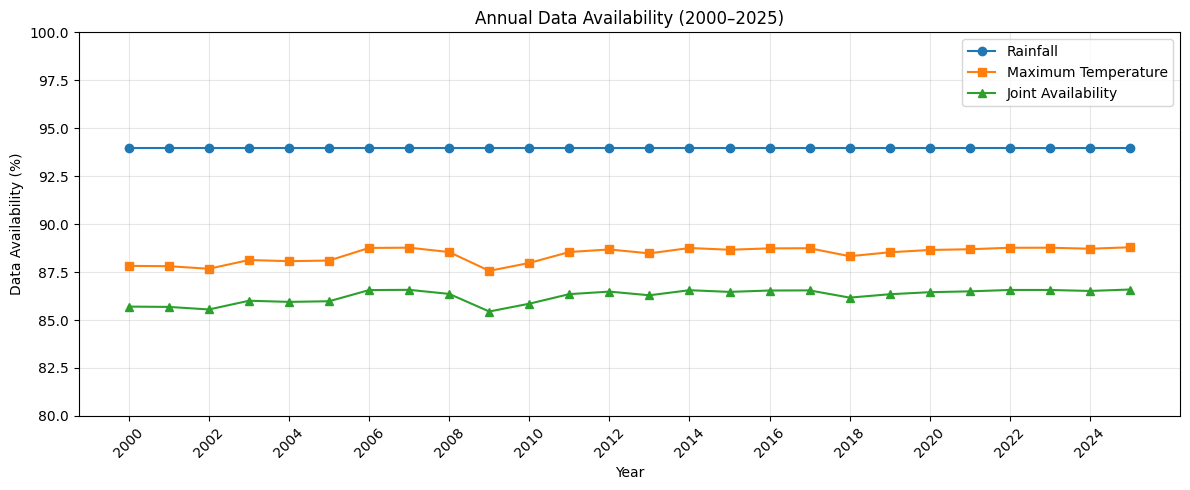

In [5]:
# Step 4: Plot annual data availability

plt.figure(figsize=(12, 5))

plt.plot(
    annual_availability["year"],
    annual_availability["rainfall_percentage"],
    marker="o",
    label="Rainfall"
)

plt.plot(
    annual_availability["year"],
    annual_availability["temperature_percentage"],
    marker="s",
    label="Maximum Temperature"
)

plt.plot(
    annual_availability["year"],
    annual_availability["joint_percentage"],
    marker="^",
    label="Joint Availability"
)

plt.xlabel("Year")
plt.ylabel("Data Availability (%)")
plt.title("Annual Data Availability (2000–2025)")

plt.xticks(range(2000, 2026, 2), rotation=45)
plt.ylim(80, 100)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Save figure
plt.savefig(
    RESULTS_DIR / "annual_data_availability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# Step 5: Spatial data availability across research nodes

# Joint availability mask
joint_mask = (
    np.isfinite(rainfall_data) &
    np.isfinite(temperature_data)
)

# Valid observations per node
node_joint_valid = joint_mask.sum(axis=0)

# Availability percentage per node
node_joint_percentage = (
    node_joint_valid / len(dates) * 100
)

# Create spatial availability DataFrame
spatial_availability = pd.DataFrame({
    "node_index": np.arange(5040),
    "latitude": climate_ds.latitude.values,
    "longitude": climate_ds.longitude.values,
    "joint_valid_days": node_joint_valid,
    "joint_availability_percentage": node_joint_percentage
})

# Summary statistics
print("Spatial availability statistics")
print("-" * 50)

print(
    spatial_availability[
        "joint_availability_percentage"
    ].describe().round(2)
)

# Availability categories
thresholds = [50, 75, 90, 95, 99, 100]

print("\nNodes meeting availability thresholds")

for threshold in thresholds:
    count = (
        spatial_availability[
            "joint_availability_percentage"
        ] >= threshold
    ).sum()

    print(
        f"Nodes with at least {threshold}% availability: "
        f"{count}"
    )

print("\nTotal research nodes:", len(spatial_availability))

Spatial availability statistics
--------------------------------------------------
count    5040.00
mean       86.25
std        34.06
min         0.00
25%        99.99
50%       100.00
75%       100.00
max       100.00
Name: joint_availability_percentage, dtype: float64

Nodes meeting availability thresholds
Nodes with at least 50% availability: 4365
Nodes with at least 75% availability: 4336
Nodes with at least 90% availability: 4320
Nodes with at least 95% availability: 4271
Nodes with at least 99% availability: 4254
Nodes with at least 100% availability: 3747

Total research nodes: 5040


,availability_category,node_count,percentage
0,0%,675,13.39
1,>0–25%,0,0.00
2,>25–50%,0,0.00
3,>50–75%,29,0.58
4,>75–90%,16,0.32
5,>90–95%,49,0.97
6,>95–99%,17,0.34
7,>99–100%,4254,84.40


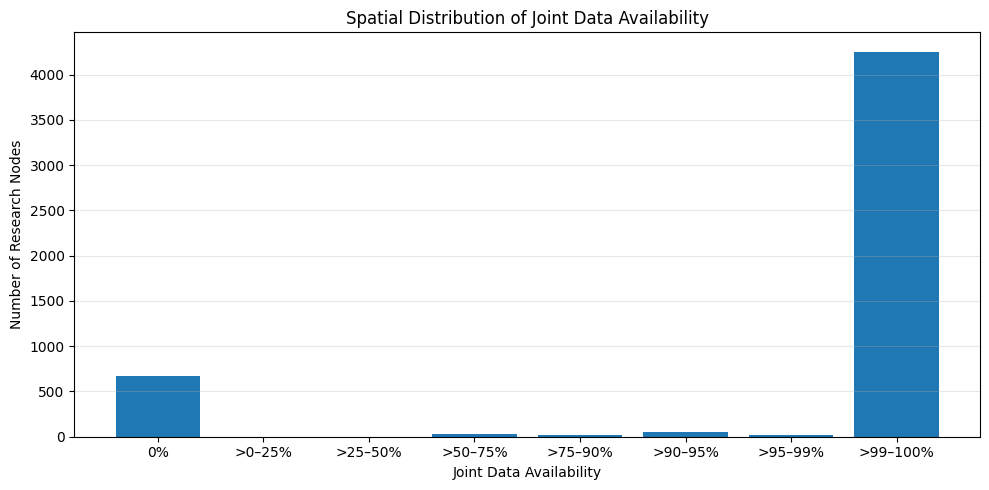

In [7]:
# Step 6: Distribution of spatial data availability

availability_bins = [
    -0.01, 0, 25, 50, 75, 90, 95, 99, 100
]

availability_labels = [
    "0%",
    ">0–25%",
    ">25–50%",
    ">50–75%",
    ">75–90%",
    ">90–95%",
    ">95–99%",
    ">99–100%"
]

spatial_availability["availability_category"] = pd.cut(
    spatial_availability["joint_availability_percentage"],
    bins=availability_bins,
    labels=availability_labels,
    include_lowest=True
)

availability_distribution = (
    spatial_availability["availability_category"]
    .value_counts(sort=False)
    .rename_axis("availability_category")
    .reset_index(name="node_count")
)

availability_distribution["percentage"] = (
    availability_distribution["node_count"] / 5040 * 100
)

display(availability_distribution.round(2))

# Visualise distribution
plt.figure(figsize=(10, 5))

plt.bar(
    availability_distribution["availability_category"].astype(str),
    availability_distribution["node_count"]
)

plt.xlabel("Joint Data Availability")
plt.ylabel("Number of Research Nodes")
plt.title("Spatial Distribution of Joint Data Availability")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "spatial_availability_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# Step 7: Identify and save low-availability nodes

# Identify nodes with zero joint observations
zero_availability_nodes = spatial_availability[
    spatial_availability["joint_valid_days"] == 0
].copy()

# Identify nodes with less than 99% availability
low_availability_nodes = spatial_availability[
    spatial_availability["joint_availability_percentage"] < 99
].copy()

# Save complete spatial availability report
spatial_availability.to_csv(
    RESULTS_DIR / "spatial_node_availability.csv",
    index=False
)

# Save zero-availability nodes separately
zero_availability_nodes.to_csv(
    RESULTS_DIR / "zero_availability_nodes.csv",
    index=False
)

print("Zero-availability nodes:", len(zero_availability_nodes))
print("Nodes below 99% availability:", len(low_availability_nodes))

print("\nZero-availability node coordinate summary")

display(
    zero_availability_nodes[
        ["latitude", "longitude"]
    ].describe().round(4)
)

print("\nFirst 15 zero-availability nodes")

display(
    zero_availability_nodes[
        ["node_index", "latitude", "longitude"]
    ].head(15)
)

print("\nSpatial availability reports saved.")

Zero-availability nodes: 675
Nodes below 99% availability: 786

Zero-availability node coordinate summary


,latitude,longitude
count,675.0000,675.0000
mean,23.7003,82.2604
std,7.9080,8.4411
min,6.8807,68.4659
25%,17.9083,74.4950
50%,25.1953,80.3595
75%,28.3365,89.7093
max,37.0023,97.3987



First 15 zero-availability nodes


,node_index,latitude,longitude
0,0,8.451258,76.834814
1,1,8.733465,76.608342
6,6,9.224103,76.354104
8,8,9.358651,76.483590
9,9,9.382370,76.326160
11,11,9.608651,76.483590
13,13,9.616170,76.307328
15,15,9.868653,76.283153
16,16,9.858651,76.483590
17,17,10.115327,76.245757



Spatial availability reports saved.


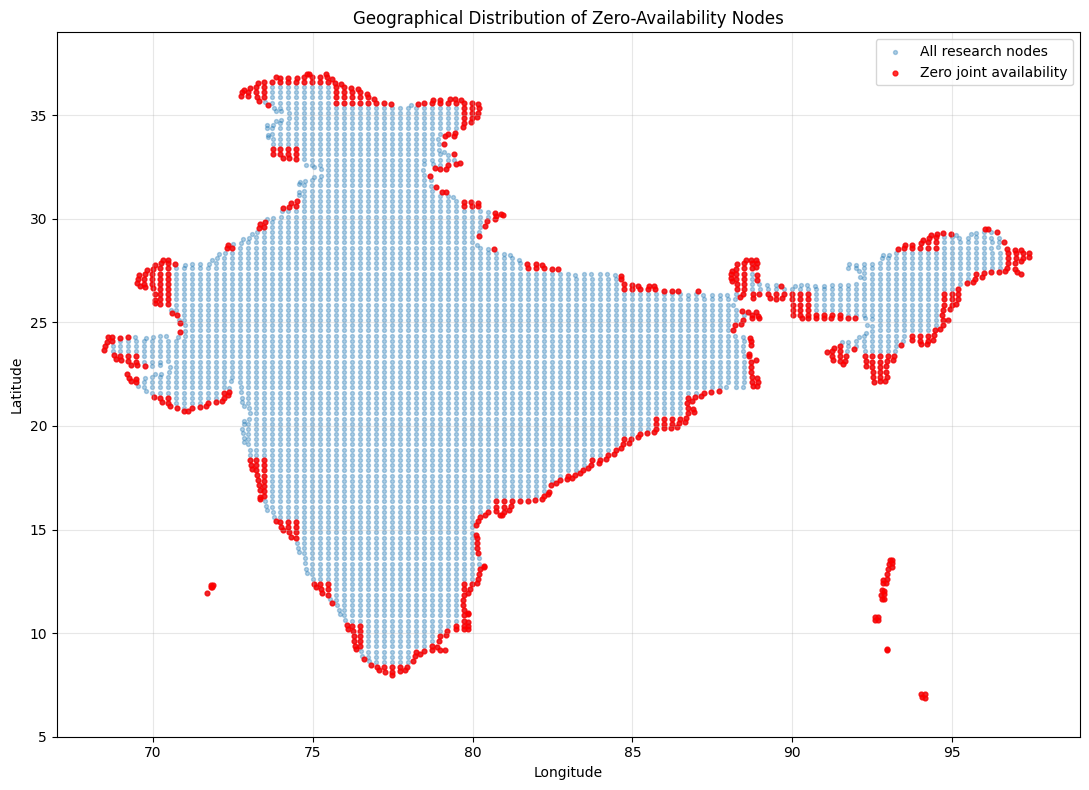

In [9]:
# Step 8: Geographical distribution of zero-availability nodes

plt.figure(figsize=(11, 8))

# All research nodes
plt.scatter(
    spatial_availability["longitude"],
    spatial_availability["latitude"],
    s=8,
    alpha=0.35,
    label="All research nodes"
)

# Zero-availability nodes
plt.scatter(
    zero_availability_nodes["longitude"],
    zero_availability_nodes["latitude"],
    s=12,
    color="red",
    alpha=0.8,
    label="Zero joint availability"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Zero-Availability Nodes")

plt.xlim(67, 99)
plt.ylim(5, 39)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "zero_availability_spatial_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Step 9: Investigate the causes of zero joint availability

rainfall_node_valid = np.isfinite(rainfall_data).sum(axis=0)
temperature_node_valid = np.isfinite(temperature_data).sum(axis=0)

zero_joint_nodes = (
    (rainfall_node_valid == 0) &
    (temperature_node_valid == 0)
)

rainfall_only_unavailable = (
    (rainfall_node_valid == 0) &
    (temperature_node_valid > 0)
)

temperature_only_unavailable = (
    (temperature_node_valid == 0) &
    (rainfall_node_valid > 0)
)

availability_causes = pd.DataFrame({
    "category": [
        "Both variables unavailable",
        "Rainfall unavailable only",
        "Temperature unavailable only"
    ],
    "node_count": [
        zero_joint_nodes.sum(),
        rainfall_only_unavailable.sum(),
        temperature_only_unavailable.sum()
    ]
})

availability_causes["percentage"] = (
    availability_causes["node_count"] / 5040 * 100
)

display(availability_causes)

print("\nVerification")
print("Total zero-joint nodes:", zero_joint_nodes.sum())
print(
    "Matches previous count:",
    zero_joint_nodes.sum() == len(zero_availability_nodes)
)

,category,node_count,percentage
0,Both variables unavailable,193,3.829365
1,Rainfall unavailable only,111,2.202381
2,Temperature unavailable only,371,7.361111



Verification
Total zero-joint nodes: 193
Matches previous count: False


In [11]:
# Step 10: Correct verification of zero joint availability

# Nodes with no simultaneous rainfall-temperature observations
joint_zero_mask = joint_mask.sum(axis=0) == 0

# Three mutually exclusive categories
both_unavailable = (
    (rainfall_node_valid == 0) &
    (temperature_node_valid == 0)
)

rainfall_unavailable_only = (
    (rainfall_node_valid == 0) &
    (temperature_node_valid > 0)
)

temperature_unavailable_only = (
    (temperature_node_valid == 0) &
    (rainfall_node_valid > 0)
)

# Combine the three categories
category_union = (
    both_unavailable |
    rainfall_unavailable_only |
    temperature_unavailable_only
)

print("Zero joint-availability nodes:", joint_zero_mask.sum())
print("Nodes covered by three categories:", category_union.sum())

print(
    "All zero-joint nodes classified:",
    np.array_equal(joint_zero_mask, category_union)
)

print(
    "Categories mutually exclusive:",
    not np.any(
        both_unavailable & rainfall_unavailable_only
    ) and not np.any(
        both_unavailable & temperature_unavailable_only
    ) and not np.any(
        rainfall_unavailable_only & temperature_unavailable_only
    )
)

Zero joint-availability nodes: 675
Nodes covered by three categories: 675
All zero-joint nodes classified: True
Categories mutually exclusive: True


In [12]:
# Step 11: Save variable-wise spatial availability

variable_availability = spatial_availability[
    ["node_index", "latitude", "longitude"]
].copy()

variable_availability["rainfall_valid_days"] = rainfall_node_valid
variable_availability["temperature_valid_days"] = temperature_node_valid
variable_availability["joint_valid_days"] = joint_mask.sum(axis=0)

variable_availability["availability_category"] = np.select(
    [
        both_unavailable,
        rainfall_unavailable_only,
        temperature_unavailable_only
    ],
    [
        "Both unavailable",
        "Rainfall unavailable only",
        "Temperature unavailable only"
    ],
    default="Joint observations available"
)

variable_availability.to_csv(
    RESULTS_DIR / "variable_wise_spatial_availability.csv",
    index=False
)

print("Variable-wise availability report saved.")
print("Total research nodes:", len(variable_availability))

display(
    variable_availability["availability_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="node_count")
)

Variable-wise availability report saved.
Total research nodes: 5040


,category,node_count
0,Joint observations available,4365
1,Temperature unavailable only,371
2,Both unavailable,193
3,Rainfall unavailable only,111


In [13]:
# Step 12: Compare individual variable spatial coverage

rainfall_available_nodes = rainfall_node_valid > 0
temperature_available_nodes = temperature_node_valid > 0

coverage_comparison = pd.DataFrame({
    "variable": ["Rainfall", "Maximum Temperature", "Joint"],
    "available_nodes": [
        rainfall_available_nodes.sum(),
        temperature_available_nodes.sum(),
        joint_mask.any(axis=0).sum()
    ]
})

coverage_comparison["unavailable_nodes"] = (
    5040 - coverage_comparison["available_nodes"]
)

coverage_comparison["coverage_percentage"] = (
    coverage_comparison["available_nodes"] / 5040 * 100
)

display(coverage_comparison.round(2))

print("\nCoverage verification")
print("Rainfall available:", rainfall_available_nodes.sum())
print("Temperature available:", temperature_available_nodes.sum())
print("Joint available:", joint_mask.any(axis=0).sum())

,variable,available_nodes,unavailable_nodes,coverage_percentage
0,Rainfall,4736,304,93.97
1,Maximum Temperature,4476,564,88.81
2,Joint,4365,675,86.61



Coverage verification
Rainfall available: 4736
Temperature available: 4476
Joint available: 4365


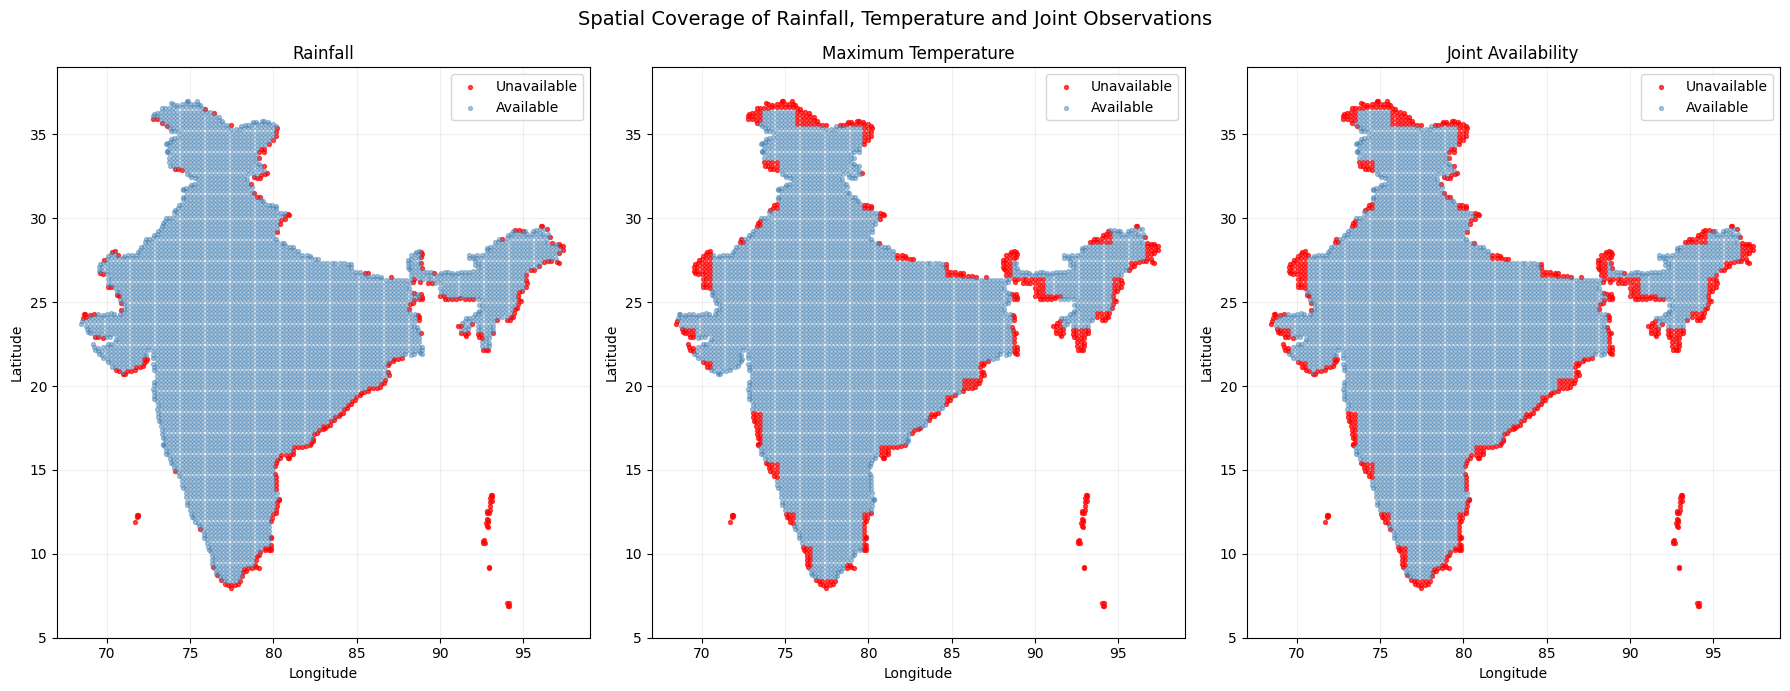

In [14]:
# Step 13: Spatial comparison of variable coverage

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

coverage_groups = [
    ("Rainfall", rainfall_available_nodes),
    ("Maximum Temperature", temperature_available_nodes),
    ("Joint Availability", joint_mask.any(axis=0))
]

for ax, (title, mask) in zip(axes, coverage_groups):

    ax.scatter(
        climate_ds.longitude.values[~mask],
        climate_ds.latitude.values[~mask],
        s=8,
        color="red",
        alpha=0.7,
        label="Unavailable"
    )

    ax.scatter(
        climate_ds.longitude.values[mask],
        climate_ds.latitude.values[mask],
        s=8,
        color="steelblue",
        alpha=0.45,
        label="Available"
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(67, 99)
    ax.set_ylim(5, 39)
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle(
    "Spatial Coverage of Rainfall, Temperature and Joint Observations",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "individual_variable_spatial_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Step 14: Overall statistical characteristics

climate_statistics = []

for variable in ["rainfall", "temperature"]:

    data = climate_ds[variable].values
    valid_data = data[np.isfinite(data)]

    climate_statistics.append({
        "variable": variable,
        "valid_observations": len(valid_data),
        "missing_observations": np.isnan(data).sum(),
        "mean": np.mean(valid_data),
        "std": np.std(valid_data),
        "minimum": np.min(valid_data),
        "25th_percentile": np.percentile(valid_data, 25),
        "median": np.median(valid_data),
        "75th_percentile": np.percentile(valid_data, 75),
        "maximum": np.max(valid_data)
    })

climate_statistics_df = pd.DataFrame(climate_statistics)

display(climate_statistics_df.round(3))

,variable,valid_observations,missing_observations,mean,std,minimum,25th_percentile,median,75th_percentile,maximum
0,rainfall,44977724,2887156,3.078,10.303,0.000,0.000000,0.00,0.744,895.567017
1,temperature,42324403,5540477,31.204,5.792,1.494,28.431999,31.49,34.639,48.431000


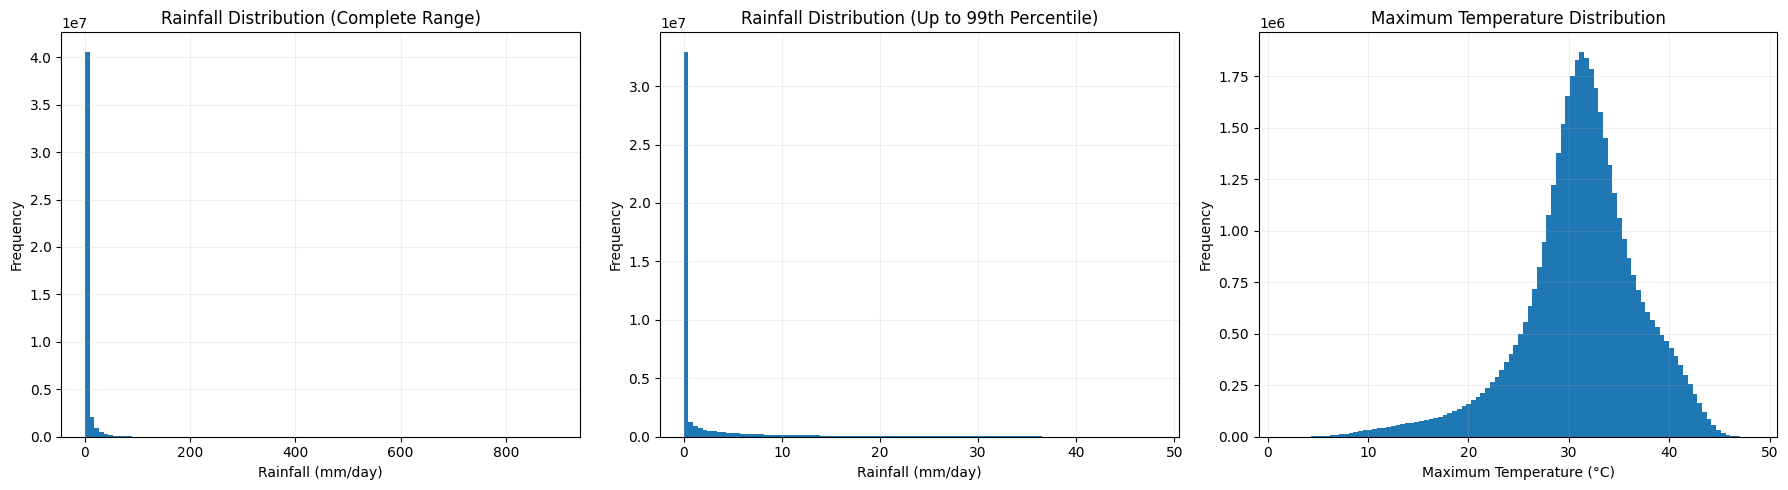

Rainfall 99th percentile: 48.038 mm/day


In [16]:
# Step 15: Visualise rainfall and temperature distributions

rainfall_valid = rainfall_data[np.isfinite(rainfall_data)]
temperature_valid = temperature_data[np.isfinite(temperature_data)]

rainfall_99 = np.percentile(rainfall_valid, 99)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Rainfall: complete range
axes[0].hist(rainfall_valid, bins=100)
axes[0].set_title("Rainfall Distribution (Complete Range)")
axes[0].set_xlabel("Rainfall (mm/day)")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.2)

# Rainfall: up to 99th percentile
axes[1].hist(
    rainfall_valid[rainfall_valid <= rainfall_99],
    bins=100
)
axes[1].set_title("Rainfall Distribution (Up to 99th Percentile)")
axes[1].set_xlabel("Rainfall (mm/day)")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.2)

# Maximum temperature
axes[2].hist(temperature_valid, bins=100)
axes[2].set_title("Maximum Temperature Distribution")
axes[2].set_xlabel("Maximum Temperature (°C)")
axes[2].set_ylabel("Frequency")
axes[2].grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "climate_variable_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Rainfall 99th percentile:", round(rainfall_99, 3), "mm/day")

In [17]:
# Step 16: Detailed rainfall distribution analysis

from scipy.stats import skew, kurtosis

rainfall_percentiles = [50, 75, 90, 95, 99, 99.5, 99.9, 100]

percentile_values = np.percentile(
    rainfall_valid,
    rainfall_percentiles
)

rainfall_distribution = pd.DataFrame({
    "percentile": rainfall_percentiles,
    "rainfall_mm_day": percentile_values
})

print("Rainfall distribution characteristics")
print("-" * 45)

print("Mean:", round(np.mean(rainfall_valid), 4))
print("Median:", round(np.median(rainfall_valid), 4))
print("Skewness:", round(skew(rainfall_valid), 4))
print("Excess kurtosis:", round(kurtosis(rainfall_valid), 4))
print(
    "Percentage of zero-rainfall observations:",
    round(np.mean(rainfall_valid == 0) * 100, 2)
)

print("\nSelected rainfall percentiles")
display(rainfall_distribution.round(3))

Rainfall distribution characteristics
---------------------------------------------
Mean: 3.0783
Median: 0.0
Skewness: 7.9457
Excess kurtosis: 118.6446
Percentage of zero-rainfall observations: 65.95

Selected rainfall percentiles


,percentile,rainfall_mm_day
0,50.0,0.000
1,75.0,0.744
2,90.0,8.647
3,95.0,18.051
4,99.0,48.038
5,99.5,65.021
6,99.9,116.280
7,100.0,895.567


In [18]:
# Step 17: Identify the 20 highest rainfall observations

rainfall_flat_indices = np.argsort(
    np.nan_to_num(
        rainfall_data,
        nan=-np.inf
    ).ravel()
)[-20:][::-1]

time_indices, node_indices = np.unravel_index(
    rainfall_flat_indices,
    rainfall_data.shape
)

extreme_rainfall = pd.DataFrame({
    "date": dates[time_indices],
    "node_index": node_indices,
    "latitude": climate_ds.latitude.values[node_indices],
    "longitude": climate_ds.longitude.values[node_indices],
    "rainfall_mm_day": rainfall_data[
        time_indices,
        node_indices
    ]
})

display(extreme_rainfall.round(3))

# Save results
extreme_rainfall.to_csv(
    RESULTS_DIR / "top_20_extreme_rainfall_observations.csv",
    index=False
)

print("\nExtreme rainfall observations saved.")

,date,node_index,latitude,longitude,rainfall_mm_day
0,2022-06-17,4631,25.359,90.984,895.567017
1,2022-06-17,4630,25.359,91.234,880.986023
2,2022-06-17,4632,25.359,90.734,876.952026
3,2022-06-15,4631,25.359,90.984,720.541992
4,2022-06-15,4632,25.359,90.734,710.374023
5,2022-06-15,4630,25.359,91.234,693.703979
6,2005-07-05,3158,29.359,79.984,636.215027
7,2005-07-27,648,19.221,72.856,628.106995
8,2014-07-08,4630,25.359,91.234,621.510986
9,2022-06-16,4631,25.359,90.984,618.900024



Extreme rainfall observations saved.


In [19]:
# Step 18: Verify extreme rainfall values against original NetCDF data

# Load the original bilinear mapping
rainfall_mapping_df = pd.read_csv(
    SPATIAL_DIR / "rainfall_bilinear_mapping.csv"
).set_index("node_index")

# Original rainfall data directory
RAW_RAINFALL_DIR = PROJECT_DIR / "data" / "raw" / "rainfall"

verification_records = []

for year in sorted(extreme_rainfall["date"].dt.year.unique()):

    source_file = (
        RAW_RAINFALL_DIR / f"RF25_ind{year}_rfp25.nc"
    )

    with xr.open_dataset(source_file) as source_ds:

        source_data = source_ds["RAINFALL"].values
        source_dates = pd.to_datetime(source_ds["TIME"].values)

        year_extremes = extreme_rainfall[
            extreme_rainfall["date"].dt.year == year
        ]

        for _, row in year_extremes.iterrows():

            node = int(row["node_index"])
            day_index = source_dates.get_loc(row["date"])

            mapping = rainfall_mapping_df.loc[node]

            r0, r1 = int(mapping["r0"]), int(mapping["r1"])
            c0, c1 = int(mapping["c0"]), int(mapping["c1"])

            corners = np.array([
                source_data[day_index, r0, c0],
                source_data[day_index, r0, c1],
                source_data[day_index, r1, c0],
                source_data[day_index, r1, c1]
            ])

            weights = np.array([
                mapping["w00"],
                mapping["w01"],
                mapping["w10"],
                mapping["w11"]
            ])

            reconstructed_value = np.sum(corners * weights)

            verification_records.append({
                "date": row["date"],
                "node_index": node,
                "saved_rainfall": row["rainfall_mm_day"],
                "source_corner_min": corners.min(),
                "source_corner_max": corners.max(),
                "reconstructed_rainfall": reconstructed_value,
                "difference": abs(
                    row["rainfall_mm_day"] - reconstructed_value
                )
            })

extreme_verification_df = pd.DataFrame(verification_records)

display(extreme_verification_df.round(3))

print("\nMaximum reconstruction difference:",
      extreme_verification_df["difference"].max())

,date,node_index,saved_rainfall,source_corner_min,source_corner_max,reconstructed_rainfall,difference
0,2005-07-05,3158,636.215,524.383,663.094,636.215,0.0
1,2005-07-27,648,628.107,423.440,732.457,628.107,0.0
2,2005-07-27,651,580.700,460.125,732.457,580.700,0.0
3,2014-07-08,4630,621.511,512.761,711.065,621.511,0.0
4,2014-07-08,4631,573.002,501.334,614.739,573.002,0.0
5,2015-08-19,4630,609.965,521.990,679.221,609.965,0.0
6,2015-08-19,4631,595.411,555.739,613.832,595.410,0.0
7,2015-08-19,4632,567.091,298.719,590.190,567.091,0.0
8,2022-06-17,4631,895.567,862.294,921.060,895.567,0.0
9,2022-06-17,4630,880.986,751.101,979.145,880.986,0.0



Maximum reconstruction difference: 3.529483467445971e-05


In [20]:
# Step 19: Save extreme rainfall verification report

extreme_verification_df.to_csv(
    RESULTS_DIR / "extreme_rainfall_source_verification.csv",
    index=False
)

print("Extreme rainfall verification report saved.")

print(
    "Maximum reconstruction difference:",
    extreme_verification_df["difference"].max()
)

print(
    "Mean reconstruction difference:",
    extreme_verification_df["difference"].mean()
)

print(
    "All differences below 0.001 mm/day:",
    (extreme_verification_df["difference"] < 0.001).all()
)

Extreme rainfall verification report saved.
Maximum reconstruction difference: 3.529483467445971e-05
Mean reconstruction difference: 1.4782267061264066e-05
All differences below 0.001 mm/day: True


In [21]:
# Step 20: Identify maximum and minimum temperature observations

temperature_flat = temperature_data.ravel()

valid_indices = np.where(np.isfinite(temperature_flat))[0]

# Highest 20 observations
highest_indices = valid_indices[
    np.argsort(temperature_flat[valid_indices])[-20:][::-1]
]

# Lowest 20 observations
lowest_indices = valid_indices[
    np.argsort(temperature_flat[valid_indices])[:20]
]


def create_temperature_extremes(indices):

    time_indices, node_indices = np.unravel_index(
        indices, temperature_data.shape
    )

    return pd.DataFrame({
        "date": dates[time_indices],
        "node_index": node_indices,
        "latitude": climate_ds.latitude.values[node_indices],
        "longitude": climate_ds.longitude.values[node_indices],
        "temperature_C": temperature_data[
            time_indices, node_indices
        ]
    })


highest_temperature = create_temperature_extremes(highest_indices)
lowest_temperature = create_temperature_extremes(lowest_indices)

print("20 Highest Maximum-Temperature Observations")
display(highest_temperature.round(3))

print("\n20 Lowest Maximum-Temperature Observations")
display(lowest_temperature.round(3))

# Save reports
highest_temperature.to_csv(
    RESULTS_DIR / "top_20_highest_temperature_observations.csv",
    index=False
)

lowest_temperature.to_csv(
    RESULTS_DIR / "top_20_lowest_temperature_observations.csv",
    index=False
)

print("\nTemperature extreme reports saved.")


20 Highest Maximum-Temperature Observations


,date,node_index,latitude,longitude,temperature_C
0,2016-05-19,2293,27.609,72.484,48.431000
1,2016-05-19,2318,27.859,72.484,48.370998
2,2016-05-19,2315,27.609,72.734,48.330002
3,2016-05-19,2314,27.609,72.234,48.327999
4,2016-05-19,2317,27.859,72.234,48.312000
5,2016-05-19,2321,28.109,72.484,48.312000
6,2016-05-19,2290,27.359,72.484,48.307999
7,2016-05-19,2319,28.109,72.234,48.296001
8,2016-05-19,2336,28.279,72.063,48.293999
9,2016-05-19,2316,27.859,72.734,48.280998



20 Lowest Maximum-Temperature Observations


,date,node_index,latitude,longitude,temperature_C
0,2008-02-07,3688,35.359,79.484,1.494
1,2005-01-23,3688,35.359,79.484,1.648
2,2005-01-23,3686,35.359,79.234,1.697
3,2008-02-07,3686,35.359,79.234,1.707
4,2005-01-23,3477,34.609,77.484,1.725
5,2005-01-23,3676,34.609,77.734,1.734
6,2005-01-23,3696,35.359,78.984,1.746
7,2005-01-23,3675,34.609,77.984,1.752
8,2005-01-23,3677,34.609,78.234,1.769
9,2008-02-08,3688,35.359,79.484,1.778



Temperature extreme reports saved.


In [22]:
# Step 21: Verify temperature extremes against original GRD files

temperature_mapping_df = pd.read_csv(
    SPATIAL_DIR / "temperature_bilinear_mapping.csv"
).set_index("node_index")

RAW_TEMPERATURE_DIR = PROJECT_DIR / "data" / "raw" / "temperature"

temperature_extremes = pd.concat(
    [highest_temperature, lowest_temperature],
    ignore_index=True
)

temperature_verification_records = []

for year in sorted(temperature_extremes["date"].dt.year.unique()):

    source_file = (
        RAW_TEMPERATURE_DIR / f"Maxtemp_MaxT_{year}.GRD"
    )

    days_in_year = 366 if pd.Timestamp(year, 12, 31).dayofyear == 366 else 365

    raw = np.fromfile(source_file, dtype="<f4")

    source_data = raw.reshape(days_in_year, 31, 31).copy()
    source_data[source_data == np.float32(99.9)] = np.nan

    year_extremes = temperature_extremes[
        temperature_extremes["date"].dt.year == year
    ]

    for _, row in year_extremes.iterrows():

        node = int(row["node_index"])
        day_index = row["date"].dayofyear - 1

        mapping = temperature_mapping_df.loc[node]

        r0, r1 = int(mapping["r0"]), int(mapping["r1"])
        c0, c1 = int(mapping["c0"]), int(mapping["c1"])

        corners = np.array([
            source_data[day_index, r0, c0],
            source_data[day_index, r0, c1],
            source_data[day_index, r1, c0],
            source_data[day_index, r1, c1]
        ])

        weights = np.array([
            mapping["w00"],
            mapping["w01"],
            mapping["w10"],
            mapping["w11"]
        ])

        reconstructed_value = np.sum(corners * weights)

        temperature_verification_records.append({
            "date": row["date"],
            "node_index": node,
            "saved_temperature": row["temperature_C"],
            "source_corner_min": corners.min(),
            "source_corner_max": corners.max(),
            "reconstructed_temperature": reconstructed_value,
            "difference": abs(
                row["temperature_C"] - reconstructed_value
            )
        })

temperature_verification_df = pd.DataFrame(
    temperature_verification_records
)

display(temperature_verification_df.round(4))

print("\nMaximum reconstruction difference:",
      temperature_verification_df["difference"].max())

,date,node_index,saved_temperature,source_corner_min,source_corner_max,reconstructed_temperature,difference
0,2005-01-23,3688,1.6484,1.460000,2.770000,1.6484,0.0
1,2005-01-23,3686,1.6971,1.460000,2.770000,1.6971,0.0
2,2005-01-23,3477,1.7254,1.680000,2.180000,1.7254,0.0
3,2005-01-23,3676,1.7343,1.680000,2.030000,1.7343,0.0
4,2005-01-23,3696,1.7458,1.460000,2.770000,1.7458,0.0
5,2005-01-23,3675,1.7517,1.680000,2.030000,1.7517,0.0
6,2005-01-23,3677,1.7691,1.680000,2.030000,1.7691,0.0
7,2005-01-23,3667,1.7865,1.680000,2.030000,1.7865,0.0
8,2005-01-23,3697,1.7946,1.460000,2.770000,1.7946,0.0
9,2005-01-23,3672,1.8051,1.680000,2.030000,1.8051,0.0



Maximum reconstruction difference: 1.566397266117292e-06


In [23]:
# Step 22: Inspect one temperature observation and its four source corners

year = 2016
node = 2293
date = pd.Timestamp("2016-05-19")
day_index = date.dayofyear - 1

source_file = RAW_TEMPERATURE_DIR / f"Maxtemp_MaxT_{year}.GRD"

raw = np.fromfile(source_file, dtype="<f4")
source_data = raw.reshape(366, 31, 31).copy()
source_data[source_data == np.float32(99.9)] = np.nan

mapping = temperature_mapping_df.loc[node]

r0, r1 = int(mapping["r0"]), int(mapping["r1"])
c0, c1 = int(mapping["c0"]), int(mapping["c1"])

corners = np.array([
    source_data[day_index, r0, c0],
    source_data[day_index, r0, c1],
    source_data[day_index, r1, c0],
    source_data[day_index, r1, c1]
])

weights = np.array([
    mapping["w00"],
    mapping["w01"],
    mapping["w10"],
    mapping["w11"]
])

saved_value = temperature_data[day_index, node]
reconstructed_value = np.sum(corners * weights)

print("Date:", date.date())
print("Node:", node)
print("Corner indices:", (r0, r1, c0, c1))
print("Source corners:", corners)
print("Interpolation weights:", weights)
print("Weight sum:", weights.sum())
print("Saved temperature:", saved_value)
print("Reconstructed temperature:", reconstructed_value)
print("Difference:", abs(saved_value - reconstructed_value))
print("Corner minimum:", np.nanmin(corners))
print("Corner maximum:", np.nanmax(corners))

Date: 2016-05-19
Node: 2293
Corner indices: (20, 21, 4, 5)
Source corners: [47.97976  48.464844 48.42151  48.215137]
Interpolation weights: [0.01462704 0.87672196 0.00178296 0.10686804]
Weight sum: 1.0
Saved temperature: 41.136894
Reconstructed temperature: 48.43098551716243
Difference: 7.294091291088215
Corner minimum: 47.97976
Corner maximum: 48.464844


In [24]:
# Step 23: Trace the temperature value across saved datasets

year = 2016
node = 2293
date = pd.Timestamp("2016-05-19")

temperature_file = (
    PROJECT_DIR / "data" / "intermediate" /
    "temperature_nodes" / f"temperature_nodes_{year}.nc"
)

integrated_file = INTEGRATED_DIR / f"integrated_climate_{year}.nc"

with xr.open_dataset(temperature_file) as temp_ds:
    print("Intermediate file variables:", list(temp_ds.data_vars))

    intermediate_value = temp_ds["temperature"].sel(
        time=date
    ).isel(node=node).item()

with xr.open_dataset(integrated_file) as int_ds:
    print("Integrated file variables:", list(int_ds.data_vars))

    integrated_value = int_ds["temperature"].sel(
        time=date
    ).isel(node=node).item()

print("\nDate:", date.date())
print("Node:", node)
print("Original GRD interpolation:", reconstructed_value)
print("Intermediate temperature:", intermediate_value)
print("Integrated temperature:", integrated_value)
print("Current in-memory temperature:", temperature_data[date.dayofyear - 1, node])

Intermediate file variables: ['temperature']
Integrated file variables: ['rainfall', 'temperature']

Date: 2016-05-19
Node: 2293
Original GRD interpolation: 48.43098551716243
Intermediate temperature: 48.43098449707031
Integrated temperature: 48.43098449707031
Current in-memory temperature: 41.136894


In [25]:
# Step 24: Check dimensions and dates of the in-memory temperature array

print("Temperature array shape:", temperature_data.shape)
print("Integrated dataset shape:", climate_ds["temperature"].shape)

print("\nTemperature array first date:", dates[0])
print("Temperature array last date:", dates[-1])

print("\nIntegrated dataset first date:", pd.to_datetime(
    climate_ds.time.values[0]
))
print("Integrated dataset last date:", pd.to_datetime(
    climate_ds.time.values[-1]
))

print("\nTemperature array value:", temperature_data[dates.get_loc(
    pd.Timestamp("2016-05-19")
), 2293])

print("Integrated dataset value:", climate_ds["temperature"].sel(
    time="2016-05-19"
).isel(node=2293).item())

Temperature array shape: (9497, 5040)
Integrated dataset shape: (9497, 5040)

Temperature array first date: 2000-01-01 00:00:00
Temperature array last date: 2025-12-31 00:00:00

Integrated dataset first date: 2000-01-01 00:00:00
Integrated dataset last date: 2025-12-31 00:00:00

Temperature array value: 48.430984
Integrated dataset value: 48.43098449707031


In [26]:
# Step 25: Reverify temperature extremes against original GRD data

temperature_extremes = pd.concat(
    [highest_temperature, lowest_temperature],
    ignore_index=True
)

temperature_verification_records = []

for year in sorted(temperature_extremes["date"].dt.year.unique()):

    source_file = RAW_TEMPERATURE_DIR / f"Maxtemp_MaxT_{year}.GRD"

    days_in_year = 366 if pd.Timestamp(year, 12, 31).dayofyear == 366 else 365

    raw = np.fromfile(source_file, dtype="<f4")
    source_data = raw.reshape(days_in_year, 31, 31).copy()
    source_data[source_data == np.float32(99.9)] = np.nan

    year_extremes = temperature_extremes[
        temperature_extremes["date"].dt.year == year
    ]

    for _, row in year_extremes.iterrows():

        node = int(row["node_index"])
        day_index = row["date"].dayofyear - 1

        mapping = temperature_mapping_df.loc[node]

        r0, r1 = int(mapping["r0"]), int(mapping["r1"])
        c0, c1 = int(mapping["c0"]), int(mapping["c1"])

        corners = np.array([
            source_data[day_index, r0, c0],
            source_data[day_index, r0, c1],
            source_data[day_index, r1, c0],
            source_data[day_index, r1, c1]
        ])

        weights = np.array([
            mapping["w00"], mapping["w01"],
            mapping["w10"], mapping["w11"]
        ])

        reconstructed_value = np.sum(corners * weights)

        saved_value = temperature_data[
            dates.get_loc(row["date"]), node
        ]

        temperature_verification_records.append({
            "date": row["date"],
            "node_index": node,
            "saved_temperature": saved_value,
            "source_corner_min": corners.min(),
            "source_corner_max": corners.max(),
            "reconstructed_temperature": reconstructed_value,
            "difference": abs(saved_value - reconstructed_value)
        })

temperature_verification_df = pd.DataFrame(
    temperature_verification_records
)

display(temperature_verification_df.round(6))

print("\nMaximum reconstruction difference:",
      temperature_verification_df["difference"].max())

print("All reconstructed values within source corner ranges:",
      np.all(
          (temperature_verification_df["reconstructed_temperature"] >=
           temperature_verification_df["source_corner_min"]) &
          (temperature_verification_df["reconstructed_temperature"] <=
           temperature_verification_df["source_corner_max"])
      ))

,date,node_index,saved_temperature,source_corner_min,source_corner_max,reconstructed_temperature,difference
0,2005-01-23,3688,1.648366,1.460000,2.770000,1.648366,0.000000
1,2005-01-23,3686,1.697101,1.460000,2.770000,1.697101,0.000000
2,2005-01-23,3477,1.725395,1.680000,2.180000,1.725395,0.000000
3,2005-01-23,3676,1.734280,1.680000,2.030000,1.734280,0.000000
4,2005-01-23,3696,1.745835,1.460000,2.770000,1.745835,0.000000
5,2005-01-23,3675,1.751675,1.680000,2.030000,1.751675,0.000000
6,2005-01-23,3677,1.769069,1.680000,2.030000,1.769069,0.000000
7,2005-01-23,3667,1.786464,1.680000,2.030000,1.786464,0.000000
8,2005-01-23,3697,1.794570,1.460000,2.770000,1.794570,0.000000
9,2005-01-23,3672,1.805112,1.680000,2.030000,1.805112,0.000000



Maximum reconstruction difference: 1.566397266117292e-06
All reconstructed values within source corner ranges: True


In [27]:
# Step 26: Save temperature extreme-value verification report

verification_file = (
    RESULTS_DIR / "temperature_extreme_source_verification.csv"
)

temperature_verification_df.to_csv(
    verification_file,
    index=False
)

print("Verification report saved:")
print(verification_file)

print("\nSummary:")
print("Observations verified:", len(temperature_verification_df))
print(
    "Maximum difference:",
    f"{temperature_verification_df['difference'].max():.8f} °C"
)
print(
    "Mean difference:",
    f"{temperature_verification_df['difference'].mean():.8f} °C"
)

Verification report saved:
D:\SVKM NMIMS Indore\Academic Related\Research Papers\Spatiotemporal GNN\New Code Setup\Spatiotemporal_GNN_Revised\results\integrated_climate_analysis\temperature_extreme_source_verification.csv

Summary:
Observations verified: 40
Maximum difference: 0.00000157 °C
Mean difference: 0.00000031 °C


In [28]:
# Step 27: Calculate monthly rainfall and temperature statistics

monthly_records = []

for month in range(1, 13):

    month_mask = dates.month == month

    rainfall_month = rainfall_data[month_mask]
    temperature_month = temperature_data[month_mask]

    rainfall_valid_month = rainfall_month[np.isfinite(rainfall_month)]
    temperature_valid_month = temperature_month[
        np.isfinite(temperature_month)
    ]

    monthly_records.append({
        "month": pd.Timestamp(2000, month, 1).strftime("%B"),
        "rainfall_mean_mm_day": np.mean(rainfall_valid_month),
        "rainfall_median_mm_day": np.median(rainfall_valid_month),
        "rainfall_valid_observations": len(rainfall_valid_month),
        "temperature_mean_C": np.mean(temperature_valid_month),
        "temperature_median_C": np.median(temperature_valid_month),
        "temperature_valid_observations": len(temperature_valid_month)
    })

monthly_statistics = pd.DataFrame(monthly_records)

display(monthly_statistics.round(3))

monthly_statistics.to_csv(
    RESULTS_DIR / "monthly_climate_statistics.csv",
    index=False
)

print("\nMonthly statistics saved successfully.")

,month,rainfall_mean_mm_day,rainfall_median_mm_day,rainfall_valid_observations,temperature_mean_C,temperature_median_C,temperature_valid_observations
0,January,0.474,0.000,3817216,24.577999,25.684999,3592651
1,February,0.683,0.000,3480960,27.923000,29.306999,3278200
2,March,0.833,0.000,3817216,32.210999,33.596001,3591458
3,April,1.327,0.000,3694080,35.991001,37.201000,3476678
4,May,2.116,0.000,3817216,37.209000,38.153000,3592629
5,June,5.395,0.175,3694080,35.150002,35.099998,3475648
6,July,8.875,2.019,3817216,31.936001,31.900000,3590074
7,August,7.856,1.550,3817216,31.245001,31.306000,3594456
8,September,5.654,0.319,3694080,31.733999,31.914000,3477654
9,October,2.320,0.000,3817148,31.691999,32.166000,3590236



Monthly statistics saved successfully.


In [29]:
# Step 28: Calculate seasonal rainfall and temperature statistics

season_months = {
    "Winter": [12, 1, 2],
    "Pre-monsoon": [3, 4, 5],
    "Monsoon": [6, 7, 8, 9],
    "Post-monsoon": [10, 11]
}

seasonal_records = []

for season, months in season_months.items():

    season_mask = dates.month.isin(months)

    rainfall_season = rainfall_data[season_mask]
    temperature_season = temperature_data[season_mask]

    rainfall_valid_season = rainfall_season[
        np.isfinite(rainfall_season)
    ]

    temperature_valid_season = temperature_season[
        np.isfinite(temperature_season)
    ]

    seasonal_records.append({
        "season": season,
        "rainfall_mean_mm_day": np.mean(rainfall_valid_season),
        "rainfall_median_mm_day": np.median(rainfall_valid_season),
        "rainfall_valid_observations": len(rainfall_valid_season),
        "temperature_mean_C": np.mean(temperature_valid_season),
        "temperature_median_C": np.median(temperature_valid_season),
        "temperature_valid_observations": len(temperature_valid_season)
    })

seasonal_statistics = pd.DataFrame(seasonal_records)

display(seasonal_statistics.round(3))

seasonal_statistics.to_csv(
    RESULTS_DIR / "seasonal_climate_statistics.csv",
    index=False
)

print("\nSeasonal statistics saved successfully.")

,season,rainfall_mean_mm_day,rainfall_median_mm_day,rainfall_valid_observations,temperature_mean_C,temperature_median_C,temperature_valid_observations
0,Winter,0.516,0.000,11115392,26.035000,27.183001,10462801
1,Pre-monsoon,1.426,0.000,11328512,35.127998,36.042999,10660765
2,Monsoon,6.968,0.861,15022592,32.500999,32.207001,14137832
3,Post-monsoon,1.580,0.000,7511228,30.344000,30.910999,7063005



Seasonal statistics saved successfully.


In [30]:
# Step 29: Calculate annual seasonal rainfall and temperature means

annual_seasonal_records = []

for year in range(2000, 2026):

    year_mask = dates.year == year

    for season, months in season_months.items():

        mask = year_mask & dates.month.isin(months)

        rainfall_values = rainfall_data[mask]
        temperature_values = temperature_data[mask]

        valid_rainfall = rainfall_values[np.isfinite(rainfall_values)]
        valid_temperature = temperature_values[
            np.isfinite(temperature_values)
        ]

        annual_seasonal_records.append({
            "year": year,
            "season": season,
            "rainfall_mean_mm_day": (
                np.mean(valid_rainfall)
                if len(valid_rainfall) > 0 else np.nan
            ),
            "temperature_mean_C": (
                np.mean(valid_temperature)
                if len(valid_temperature) > 0 else np.nan
            ),
            "rainfall_valid_observations": len(valid_rainfall),
            "temperature_valid_observations": len(valid_temperature)
        })

annual_seasonal_statistics = pd.DataFrame(
    annual_seasonal_records
)

display(annual_seasonal_statistics.head(12).round(3))

annual_seasonal_statistics.to_csv(
    RESULTS_DIR / "annual_seasonal_climate_statistics.csv",
    index=False
)

print("\nTotal records:", len(annual_seasonal_statistics))
print("Years:", annual_seasonal_statistics["year"].nunique())
print("Seasons:", annual_seasonal_statistics["season"].nunique())
print("Annual seasonal statistics saved successfully.")

,year,season,rainfall_mean_mm_day,temperature_mean_C,rainfall_valid_observations,temperature_valid_observations
0,2000,Winter,0.515,25.813999,430976,402792
1,2000,Pre-monsoon,1.265,34.909000,435712,407068
2,2000,Monsoon,6.393,31.912001,577792,540094
3,2000,Post-monsoon,0.892,31.261000,288896,270047
4,2001,Winter,0.243,26.514000,426240,398207
5,2001,Pre-monsoon,1.304,34.823002,435712,407068
6,2001,Monsoon,6.516,32.021999,577792,539981
7,2001,Post-monsoon,1.913,30.572001,288896,270015
8,2002,Winter,0.471,26.298000,426240,396977
9,2002,Pre-monsoon,1.330,35.398998,435712,407252



Total records: 104
Years: 26
Seasons: 4
Annual seasonal statistics saved successfully.


In [31]:
# Step 30: Summarise interannual seasonal variability

seasonal_variability = (
    annual_seasonal_statistics
    .groupby("season")
    .agg(
        rainfall_26yr_mean=("rainfall_mean_mm_day", "mean"),
        rainfall_26yr_std=("rainfall_mean_mm_day", "std"),
        rainfall_min=("rainfall_mean_mm_day", "min"),
        rainfall_max=("rainfall_mean_mm_day", "max"),
        temperature_26yr_mean=("temperature_mean_C", "mean"),
        temperature_26yr_std=("temperature_mean_C", "std"),
        temperature_min=("temperature_mean_C", "min"),
        temperature_max=("temperature_mean_C", "max")
    )
    .reindex(["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"])
    .reset_index()
)

display(seasonal_variability.round(3))

seasonal_variability.to_csv(
    RESULTS_DIR / "seasonal_interannual_variability.csv",
    index=False
)

print("\nSeasonal interannual variability summary saved.")

,season,rainfall_26yr_mean,rainfall_26yr_std,rainfall_min,rainfall_max,temperature_26yr_mean,temperature_26yr_std,temperature_min,temperature_max
0,Winter,0.517,0.154,0.243,0.914,26.035999,0.615,24.957001,27.304001
1,Pre-monsoon,1.426,0.236,1.087,2.062,35.127998,0.658,33.828999,36.894001
2,Monsoon,6.968,0.622,5.626,7.836,32.500999,0.432,31.792999,33.466999
3,Post-monsoon,1.580,0.491,0.842,2.502,30.344000,0.541,29.318001,31.261000



Seasonal interannual variability summary saved.


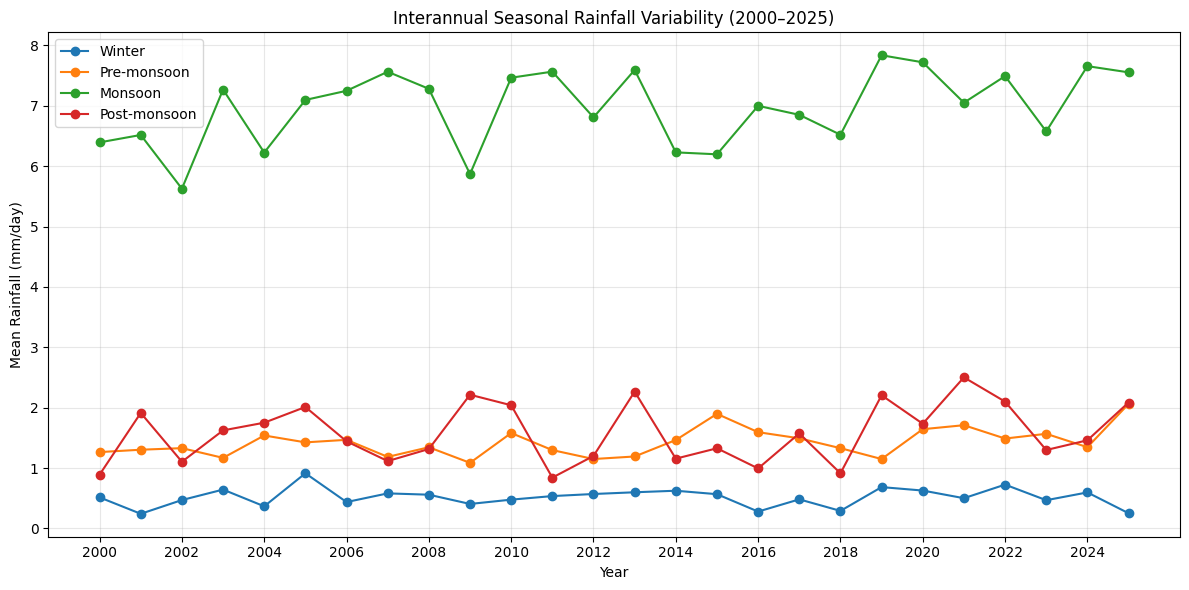

In [32]:
# Step 31: Plot annual seasonal rainfall and temperature patterns

import matplotlib.pyplot as plt

seasons_order = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

fig, ax = plt.subplots(figsize=(12, 6))

for season in seasons_order:
    subset = annual_seasonal_statistics[
        annual_seasonal_statistics["season"] == season
    ]

    ax.plot(
        subset["year"],
        subset["rainfall_mean_mm_day"],
        marker="o",
        label=season
    )

ax.set_title("Interannual Seasonal Rainfall Variability (2000–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean Rainfall (mm/day)")
ax.set_xticks(range(2000, 2026, 2))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "interannual_seasonal_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

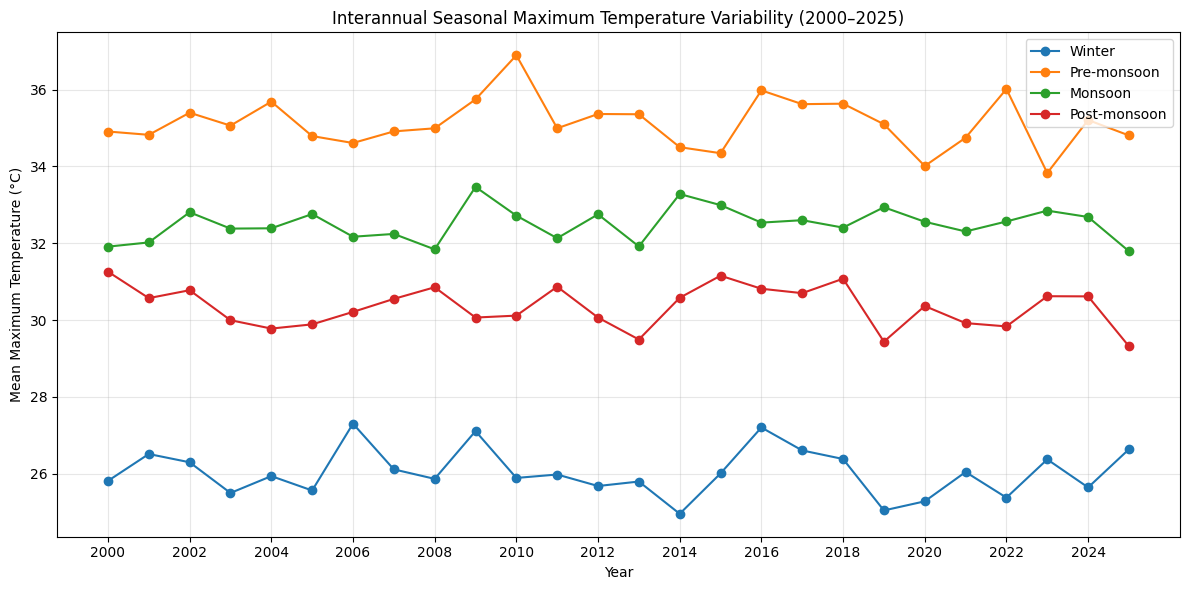

In [33]:
# Step 32: Plot annual seasonal temperature patterns

fig, ax = plt.subplots(figsize=(12, 6))

for season in seasons_order:
    subset = annual_seasonal_statistics[
        annual_seasonal_statistics["season"] == season
    ]

    ax.plot(
        subset["year"],
        subset["temperature_mean_C"],
        marker="o",
        label=season
    )

ax.set_title("Interannual Seasonal Maximum Temperature Variability (2000–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean Maximum Temperature (°C)")
ax.set_xticks(range(2000, 2026, 2))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "interannual_seasonal_temperature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Step 33: Calculate annual rainfall-temperature correlations

from scipy.stats import pearsonr, spearmanr

annual_correlation_records = []

for year in range(2000, 2026):

    year_mask = dates.year == year

    rainfall_year = rainfall_data[year_mask]
    temperature_year = temperature_data[year_mask]

    valid_mask = (
        np.isfinite(rainfall_year) &
        np.isfinite(temperature_year)
    )

    rainfall_valid_year = rainfall_year[valid_mask]
    temperature_valid_year = temperature_year[valid_mask]

    pearson_r, pearson_p = pearsonr(
        rainfall_valid_year,
        temperature_valid_year
    )

    spearman_r, spearman_p = spearmanr(
        rainfall_valid_year,
        temperature_valid_year
    )

    annual_correlation_records.append({
        "year": year,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p,
        "joint_valid_observations": len(rainfall_valid_year)
    })

annual_correlations = pd.DataFrame(
    annual_correlation_records
)

display(annual_correlations.round(4))

annual_correlations.to_csv(
    RESULTS_DIR / "annual_rainfall_temperature_correlations.csv",
    index=False
)

print("\nMean annual Pearson correlation:",
      annual_correlations["pearson_r"].mean())

print("Mean annual Spearman correlation:",
      annual_correlations["spearman_r"].mean())


,year,pearson_r,pearson_p,spearman_r,spearman_p,joint_valid_observations
0,2000,-0.0635,0.0,-0.0799,0.0,1580840
1,2001,-0.0424,0.0,-0.0466,0.0,1576221
2,2002,-0.0857,0.0,-0.0976,0.0,1573762
3,2003,-0.0624,0.0,-0.0887,0.0,1582144
4,2004,-0.0709,0.0,-0.0736,0.0,1585380
5,2005,-0.0923,0.0,-0.1169,0.0,1581646
6,2006,-0.1119,0.0,-0.1345,0.0,1592359
7,2007,-0.0795,0.0,-0.0812,0.0,1592600
8,2008,-0.0630,0.0,-0.0878,0.0,1593045
9,2009,-0.0916,0.0,-0.1170,0.0,1571813



Mean annual Pearson correlation: -0.07420192
Mean annual Spearman correlation: -0.08213003492132884


In [35]:
# Step 34: Calculate seasonal rainfall-temperature correlations

seasonal_correlation_records = []

for season, months in season_months.items():

    season_mask = dates.month.isin(months)

    rainfall_season = rainfall_data[season_mask]
    temperature_season = temperature_data[season_mask]

    valid_mask = (
        np.isfinite(rainfall_season) &
        np.isfinite(temperature_season)
    )

    rainfall_valid_season = rainfall_season[valid_mask]
    temperature_valid_season = temperature_season[valid_mask]

    pearson_r, pearson_p = pearsonr(
        rainfall_valid_season,
        temperature_valid_season
    )

    spearman_r, spearman_p = spearmanr(
        rainfall_valid_season,
        temperature_valid_season
    )

    seasonal_correlation_records.append({
        "season": season,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p,
        "joint_valid_observations": len(rainfall_valid_season)
    })

seasonal_correlations = pd.DataFrame(
    seasonal_correlation_records
)

display(seasonal_correlations.round(5))

seasonal_correlations.to_csv(
    RESULTS_DIR / "seasonal_rainfall_temperature_correlations.csv",
    index=False
)

print("\nSeasonal correlation results saved successfully.")

,season,pearson_r,pearson_p,spearman_r,spearman_p,joint_valid_observations
0,Winter,-0.16135,0.0,-0.22024,0.0,10205756
1,Pre-monsoon,-0.22716,0.0,-0.32180,0.0,10398987
2,Monsoon,-0.27210,0.0,-0.39723,0.0,13790471
3,Post-monsoon,-0.08687,0.0,-0.12708,0.0,6889335



Seasonal correlation results saved successfully.


In [36]:
# Step 35: Calculate node-wise rainfall-temperature correlations

node_correlation_records = []

for node in range(rainfall_data.shape[1]):

    rainfall_node = rainfall_data[:, node]
    temperature_node = temperature_data[:, node]

    valid_mask = (
        np.isfinite(rainfall_node) &
        np.isfinite(temperature_node)
    )

    rainfall_valid_node = rainfall_node[valid_mask]
    temperature_valid_node = temperature_node[valid_mask]

    if len(rainfall_valid_node) >= 30:

        pearson_r = np.corrcoef(
            rainfall_valid_node,
            temperature_valid_node
        )[0, 1]

        spearman_r = spearmanr(
            rainfall_valid_node,
            temperature_valid_node
        ).statistic

    else:
        pearson_r = np.nan
        spearman_r = np.nan

    node_correlation_records.append({
        "node_index": node,
        "latitude": climate_ds.latitude.values[node],
        "longitude": climate_ds.longitude.values[node],
        "joint_valid_days": len(rainfall_valid_node),
        "pearson_r": pearson_r,
        "spearman_r": spearman_r
    })

node_correlations = pd.DataFrame(node_correlation_records)

display(node_correlations.head(10).round(4))

print("\nNodes analysed:", len(node_correlations))
print("Nodes with valid correlations:",
      node_correlations["pearson_r"].notna().sum())
print("Mean node-wise Pearson correlation:",
      node_correlations["pearson_r"].mean())
print("Median node-wise Pearson correlation:",
      node_correlations["pearson_r"].median())

,node_index,latitude,longitude,joint_valid_days,pearson_r,spearman_r
0,0,8.4513,76.8348,0,NaN,NaN
1,1,8.7335,76.6083,0,NaN,NaN
2,2,8.6319,76.7705,9497,-0.3499,-0.3566
3,3,8.8855,76.5470,9497,-0.3627,-0.3926
4,4,8.8587,76.7336,9497,-0.3324,-0.3450
5,5,9.1087,76.7336,9497,-0.3196,-0.3351
6,6,9.2241,76.3541,0,NaN,NaN
7,7,9.1190,76.5033,9497,-0.3982,-0.4207
8,8,9.3587,76.4836,0,NaN,NaN
9,9,9.3824,76.3262,0,NaN,NaN



Nodes analysed: 5040
Nodes with valid correlations: 4365
Mean node-wise Pearson correlation: -0.10069867285820343
Median node-wise Pearson correlation: -0.10794472454875685


In [37]:
# Step 36: Summarise the distribution of node-wise correlations

valid_node_correlations = node_correlations.dropna(
    subset=["pearson_r"]
).copy()

negative_nodes = (
    valid_node_correlations["pearson_r"] < 0
).sum()

positive_nodes = (
    valid_node_correlations["pearson_r"] > 0
).sum()

near_zero_nodes = (
    valid_node_correlations["pearson_r"].abs() <= 0.05
).sum()

print("Total nodes:", len(node_correlations))
print("Valid correlation nodes:", len(valid_node_correlations))

print("\nPearson correlation distribution:")
print("Negative nodes:", negative_nodes)
print("Positive nodes:", positive_nodes)
print("Near-zero nodes (|r| <= 0.05):", near_zero_nodes)

print("\nPercentage distribution:")
print("Negative:", round(100 * negative_nodes / len(valid_node_correlations), 2), "%")
print("Positive:", round(100 * positive_nodes / len(valid_node_correlations), 2), "%")
print("Near-zero:", round(100 * near_zero_nodes / len(valid_node_correlations), 2), "%")

print("\nCorrelation statistics:")
display(
    valid_node_correlations["pearson_r"]
    .describe()
    .round(4)
)

Total nodes: 5040
Valid correlation nodes: 4365

Pearson correlation distribution:
Negative nodes: 3365
Positive nodes: 1000
Near-zero nodes (|r| <= 0.05): 1213

Percentage distribution:
Negative: 77.09 %
Positive: 22.91 %
Near-zero: 27.79 %

Correlation statistics:


count    4365.0000
mean       -0.1007
std         0.1260
min        -0.6545
25%        -0.1824
50%        -0.1079
75%        -0.0053
max         0.2525
Name: pearson_r, dtype: float64

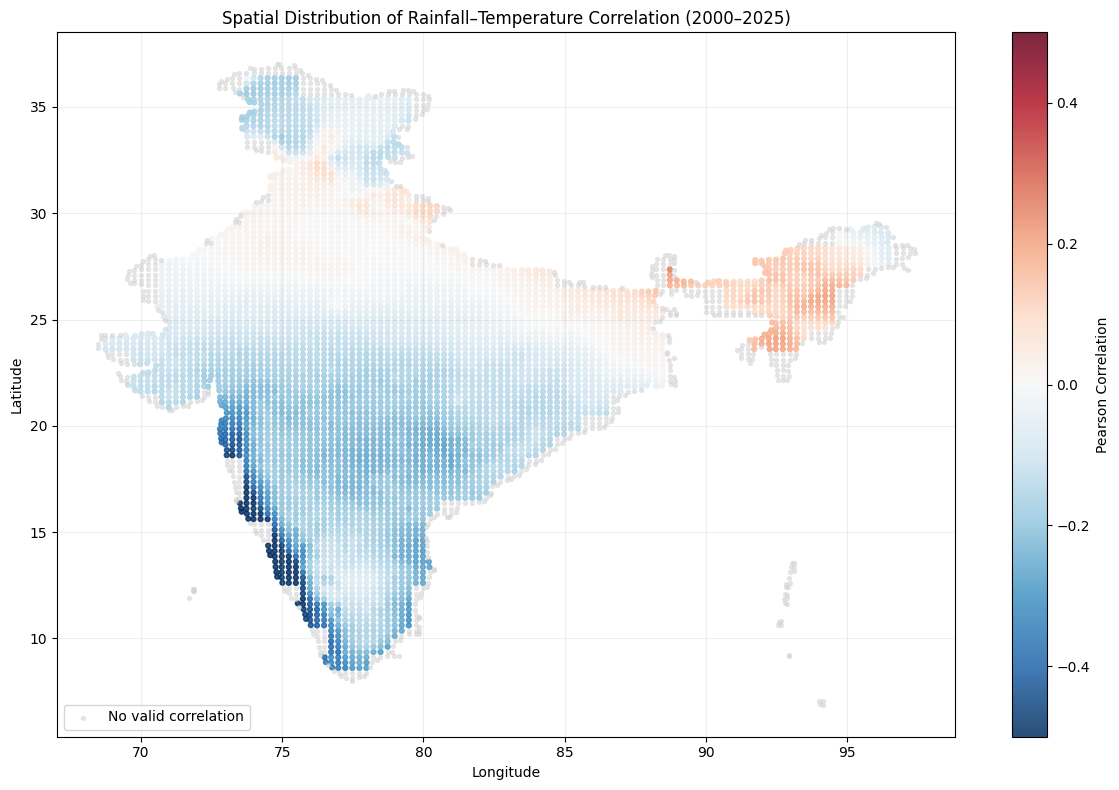

In [38]:
# Step 37: Spatial distribution of node-wise rainfall-temperature correlations

fig, ax = plt.subplots(figsize=(12, 8))

valid = node_correlations.dropna(subset=["pearson_r"])

scatter = ax.scatter(
    valid["longitude"],
    valid["latitude"],
    c=valid["pearson_r"],
    cmap="RdBu_r",
    vmin=-0.5,
    vmax=0.5,
    s=12,
    alpha=0.85
)

unavailable = node_correlations[
    node_correlations["pearson_r"].isna()
]

ax.scatter(
    unavailable["longitude"],
    unavailable["latitude"],
    color="lightgrey",
    s=8,
    alpha=0.5,
    label="No valid correlation"
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Pearson Correlation")

ax.set_title(
    "Spatial Distribution of Rainfall–Temperature Correlation (2000–2025)"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower left")
ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "spatial_rainfall_temperature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
# Step 38: Calculate annual rainfall and temperature statistics

annual_climate_records = []

for year in range(2000, 2026):

    year_mask = dates.year == year

    rainfall_year = rainfall_data[year_mask]
    temperature_year = temperature_data[year_mask]

    rainfall_valid_year = rainfall_year[np.isfinite(rainfall_year)]
    temperature_valid_year = temperature_year[np.isfinite(temperature_year)]

    annual_climate_records.append({
        "year": year,

        "rainfall_valid_observations": len(rainfall_valid_year),
        "rainfall_mean": np.mean(rainfall_valid_year),
        "rainfall_std": np.std(rainfall_valid_year),
        "rainfall_median": np.median(rainfall_valid_year),

        "temperature_valid_observations": len(temperature_valid_year),
        "temperature_mean": np.mean(temperature_valid_year),
        "temperature_std": np.std(temperature_valid_year),
        "temperature_median": np.median(temperature_valid_year)
    })

annual_climate_statistics = pd.DataFrame(
    annual_climate_records
)

annual_climate_statistics.to_csv(
    RESULTS_DIR / "annual_climate_statistics.csv",
    index=False
)

display(annual_climate_statistics.round(3))

,year,rainfall_valid_observations,rainfall_mean,rainfall_std,rainfall_median,temperature_valid_observations,temperature_mean,temperature_std,temperature_median
0,2000,1733376,2.726,9.297,0.0,1620001,31.040001,5.624,31.430000
1,2001,1728640,2.886,9.611,0.0,1615271,31.127001,5.326,31.455999
2,2002,1728640,2.516,9.246,0.0,1612805,31.521000,5.856,31.652000
3,2003,1728640,3.154,10.081,0.0,1621199,30.962000,6.187,31.267000
4,2004,1733376,2.845,9.668,0.0,1624532,31.177999,5.813,31.469000
5,2005,1728640,3.293,11.544,0.0,1620690,31.017000,6.075,31.172001
6,2006,1728640,3.141,11.183,0.0,1632798,31.257000,5.400,31.445000
7,2007,1728640,3.156,11.112,0.0,1633031,31.120001,5.620,31.370001
8,2008,1733376,3.123,10.112,0.0,1633298,30.983999,5.561,31.493999
9,2009,1728640,2.706,9.909,0.0,1610835,31.903000,5.674,32.110001


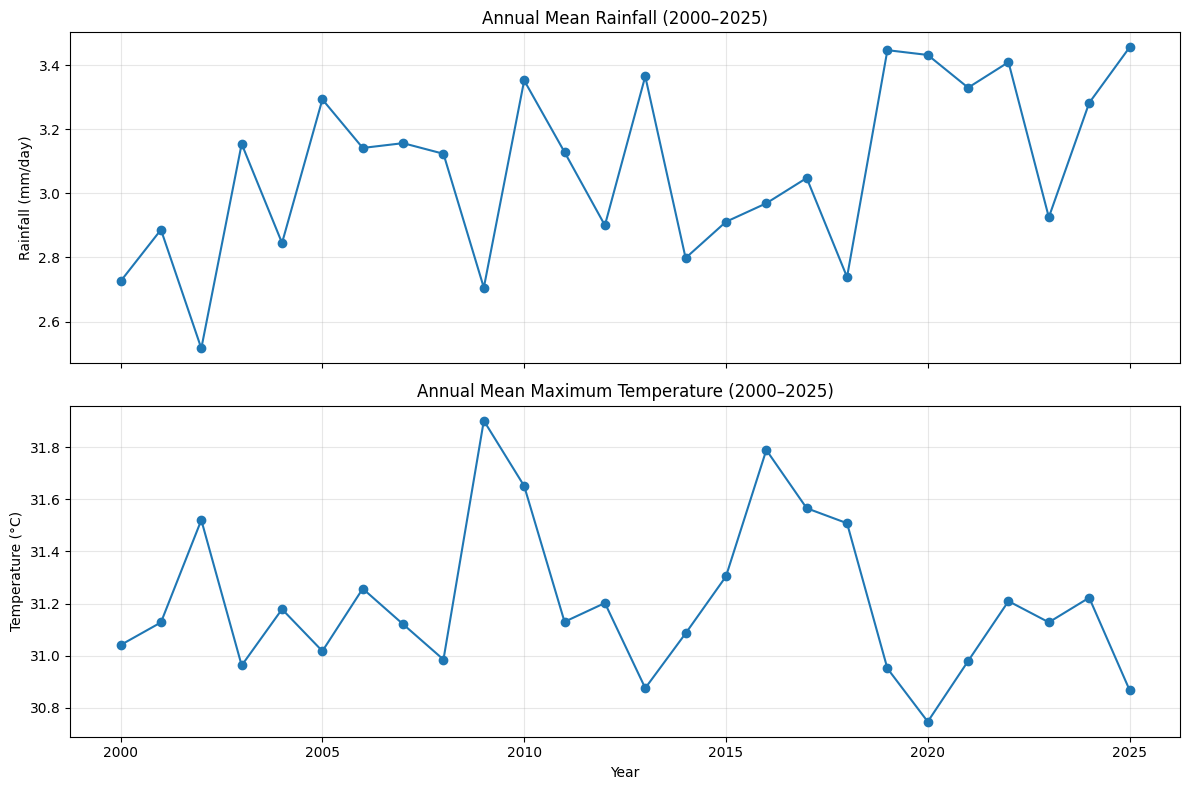

In [40]:
# Step 39: Plot annual mean rainfall and temperature

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Annual rainfall
axes[0].plot(
    annual_climate_statistics["year"],
    annual_climate_statistics["rainfall_mean"],
    marker="o"
)

axes[0].set_title("Annual Mean Rainfall (2000–2025)")
axes[0].set_ylabel("Rainfall (mm/day)")
axes[0].grid(alpha=0.3)

# Annual maximum temperature
axes[1].plot(
    annual_climate_statistics["year"],
    annual_climate_statistics["temperature_mean"],
    marker="o"
)

axes[1].set_title("Annual Mean Maximum Temperature (2000–2025)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Temperature (°C)")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "annual_rainfall_temperature_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# Step 40: Mann-Kendall test and Sen's slope

from scipy.stats import kendalltau, theilslopes

trend_results = []

for variable, column in [
    ("Rainfall", "rainfall_mean"),
    ("Maximum Temperature", "temperature_mean")
]:

    series = annual_climate_statistics[column].values
    years = annual_climate_statistics["year"].values

    # Mann-Kendall trend test
    tau, p_value = kendalltau(years, series)

    # Sen's slope
    slope, intercept, low_slope, high_slope = theilslopes(
        series, years
    )

    trend_results.append({
        "variable": variable,
        "kendall_tau": tau,
        "p_value": p_value,
        "sen_slope_per_year": slope,
        "sen_slope_lower_95": low_slope,
        "sen_slope_upper_95": high_slope
    })

trend_results_df = pd.DataFrame(trend_results)

display(trend_results_df.round(5))

,variable,kendall_tau,p_value,sen_slope_per_year,sen_slope_lower_95,sen_slope_upper_95
0,Rainfall,0.32923,0.01837,0.01559,0.00228,0.03133
1,Maximum Temperature,-0.05231,0.72697,-0.00265,-0.01789,0.01241


In [42]:
# Step 41: Check lag-1 temporal autocorrelation in annual climate statistics

from scipy.stats import pearsonr, spearmanr

autocorrelation_results = []

for variable, column in [
    ("Rainfall", "rainfall_mean"),
    ("Maximum Temperature", "temperature_mean")
]:

    values = annual_climate_statistics[column].values

    current_values = values[1:]
    previous_values = values[:-1]

    pearson_r, pearson_p = pearsonr(
        previous_values, current_values
    )

    spearman_r, spearman_p = spearmanr(
        previous_values, current_values
    )

    autocorrelation_results.append({
        "variable": variable,
        "lag1_pearson_r": pearson_r,
        "lag1_pearson_p": pearson_p,
        "lag1_spearman_r": spearman_r,
        "lag1_spearman_p": spearman_p
    })

autocorrelation_df = pd.DataFrame(autocorrelation_results)

display(autocorrelation_df.round(4))

,variable,lag1_pearson_r,lag1_pearson_p,lag1_spearman_r,lag1_spearman_p
0,Rainfall,0.0589,0.7797,0.0669,0.7506
1,Maximum Temperature,0.2890,0.1611,0.1685,0.4208


In [43]:
# Step 42: Examine daily joint rainfall-temperature availability

daily_joint_valid = joint_mask.sum(axis=1)

daily_joint_availability = (
    daily_joint_valid / rainfall_data.shape[1]
) * 100

print("Daily joint availability summary:")
print(
    pd.Series(daily_joint_availability).describe().round(3)
)

print("\nDaily availability thresholds:")

for threshold in [70, 75, 80, 85, 90, 95, 99, 100]:

    count = np.sum(daily_joint_availability >= threshold)

    print(
        f"Days with at least {threshold}% availability: "
        f"{count} ({count / len(daily_joint_availability) * 100:.2f}%)"
    )

print("\nDays with less than 75% availability:",
      np.sum(daily_joint_availability < 75))

print("Days with less than 50% availability:",
      np.sum(daily_joint_availability < 50))

Daily joint availability summary:
count    9497.000
mean       86.252
std         0.497
min        80.278
25%        86.032
50%        86.607
75%        86.607
max        86.607
dtype: float64

Daily availability thresholds:
Days with at least 70% availability: 9497 (100.00%)
Days with at least 75% availability: 9497 (100.00%)
Days with at least 80% availability: 9497 (100.00%)
Days with at least 85% availability: 9364 (98.60%)
Days with at least 90% availability: 0 (0.00%)
Days with at least 95% availability: 0 (0.00%)
Days with at least 99% availability: 0 (0.00%)
Days with at least 100% availability: 0 (0.00%)

Days with less than 75% availability: 0
Days with less than 50% availability: 0


In [44]:
# Step 43: Monthly joint data availability

monthly_availability = []

for month in range(1, 13):

    month_mask = dates.month == month

    valid_count = joint_mask[month_mask].sum()
    total_count = joint_mask[month_mask].size

    monthly_availability.append({
        "month": month,
        "valid_observations": valid_count,
        "total_observations": total_count,
        "availability_percentage": (
            valid_count / total_count
        ) * 100
    })

monthly_availability_df = pd.DataFrame(
    monthly_availability
)

display(monthly_availability_df.round(3))

,month,valid_observations,total_observations,availability_percentage
0,1,3504283,4062240,86.265
1,2,3197629,3704400,86.320
2,3,3503232,4062240,86.239
3,4,3391401,3931200,86.269
4,5,3504354,4062240,86.267
5,6,3390292,3931200,86.241
6,7,3501808,4062240,86.204
7,8,3506150,4062240,86.311
8,9,3392221,3931200,86.290
9,10,3501876,4062240,86.206


In [47]:
# Step 44: Save temporal availability summaries (corrected)

daily_availability_values = (
    joint_mask.sum(axis=1) / joint_mask.shape[1]
) * 100

daily_summary = pd.DataFrame({
    "metric": [
        "mean_daily_availability",
        "minimum_daily_availability",
        "maximum_daily_availability",
        "std_daily_availability",
        "days_below_75_percent",
        "days_below_50_percent"
    ],
    "value": [
        daily_availability_values.mean(),
        daily_availability_values.min(),
        daily_availability_values.max(),
        daily_availability_values.std(),
        np.sum(daily_availability_values < 75),
        np.sum(daily_availability_values < 50)
    ]
})

daily_summary.to_csv(
    RESULTS_DIR / "daily_availability_summary.csv",
    index=False
)

monthly_availability_df.to_csv(
    RESULTS_DIR / "monthly_availability_summary.csv",
    index=False
)

print("Temporal availability summaries saved successfully.")

display(daily_summary.round(4))

Temporal availability summaries saved successfully.


,metric,value
0,mean_daily_availability,86.2523
1,minimum_daily_availability,80.2778
2,maximum_daily_availability,86.6071
3,std_daily_availability,0.4968
4,days_below_75_percent,0.0000
5,days_below_50_percent,0.0000


In [48]:
# Step 45: Verify annual temporal coverage

annual_temporal_coverage = pd.DataFrame({
    "year": range(2000, 2026),
    "number_of_days": [
        np.sum(dates.year == year)
        for year in range(2000, 2026)
    ]
})

annual_temporal_coverage["expected_days"] = [
    366 if pd.Timestamp(year, 12, 31).is_leap_year else 365
    for year in annual_temporal_coverage["year"]
]

annual_temporal_coverage["coverage_check"] = (
    annual_temporal_coverage["number_of_days"]
    == annual_temporal_coverage["expected_days"]
)

display(annual_temporal_coverage)

print(
    "\nAll years complete:",
    annual_temporal_coverage["coverage_check"].all()
)

,year,number_of_days,expected_days,coverage_check
0,2000,366,366,True
1,2001,365,365,True
2,2002,365,365,True
3,2003,365,365,True
4,2004,366,366,True
5,2005,365,365,True
6,2006,365,365,True
7,2007,365,365,True
8,2008,366,366,True
9,2009,365,365,True



All years complete: True
